:::{admonition} Run this notebook yourself!
:class: important

Download the executed notebook: **{nb-download}`ds_vwidelines.ipynb`**!

Run it in your browser: **{binder}`ds_vwidelines.ipynb`**!

:::

# vwidelines

In this notebook, we will create a datasaurus metamer shaped like two  wide vertical lines.


The penalty here is the most complex in this series of notebooks, so you're encouraged to read others first (especially [](ds_polygons.md), [](ds_oval.md), and one of [](ds_hlines.md), [](ds_vlines.md), [](ds_slantdown.md), [](ds_slantup.md), or [](ds_xshape.md)).

In [1]:
import einops
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import torch

import plenoptic as po

# so that relative sizes of axes created by po.plot.imshow and others look right
plt.rcParams["figure.dpi"] = 72

plt.rcParams["animation.html"] = "html5"
# use single-threaded ffmpeg for animation writer
plt.rcParams["animation.writer"] = "ffmpeg"
plt.rcParams["animation.ffmpeg_args"] = ["-threads", "1"]
plt.rcParams["savefig.bbox"] = "tight"

po.set_seed(0)
# To guarantee reproducibility for this example on the GPU, we must tell torch to use
# deterministic algorithms. Note this will make things slower! See "Reproducibility and
# Compatibility" in the docs for more details.
torch.use_deterministic_algorithms(True)


# Model definition, as in top-level notebook
class DatasaurusModel(torch.nn.Module):
    def __init__(self, n_pts=None, dtype=None, include_redundant_stats=True):
        """
        Create model to measure datasaurus stats.

        Parameters
        ----------
        n_pts
            Number of data points in the dataset we'll use the model for. Used to cache
            a corresponding vector of ones for computing linear regression.
        dtype
            dtype for the dataset we'll use the model for. Used to cache
            a corresponding vector of ones for computing linear regression.
        include_redundant_stats
            Whether to include the redundant stats (linear regression slope and
            intercept, coefficient of determination).
        """
        super().__init__()
        # cache ones to save time
        if n_pts is not None:
            self._ones = torch.ones(n_pts, dtype=dtype)
        else:
            self._ones = None
        self.include_redundant_stats = include_redundant_stats
        # This model has no trainable parameters, so it's always in eval mode
        self.eval()

    def _prepare_X(self, x):
        """Append vector of ones to matrix for linear regression (for intercept)."""
        ones = self._ones if self._ones is None else torch.ones_like(x)
        return torch.stack([ones, x], -1)

    def _compute_linreg(self, x, y):
        """Compute linear regression (with intercept) between x and y."""
        X = self._prepare_X(x)
        # unsqueezing and squeezing needed because of https://github.com/pytorch/pytorch/issues/158169
        return torch.linalg.lstsq(X, y.unsqueeze(-1)).solution.squeeze()

    def _compute_coeff_determination(self, x, y, solution):
        """Compute R^2 for linera regression fit."""
        X = self._prepare_X(x)
        pred_y = torch.einsum("x, n x -> n", solution, X)
        ss_res = (y - pred_y).pow(2).sum()
        ss_tot = (y - y.mean()).pow(2).sum()
        return 1 - (ss_res / ss_tot)

    def _vmap_coeff_determination(self, x, solution):
        """vmap _compute_coeff_determiniation across dim=0."""
        f = torch.func.vmap(lambda x, solt: self._compute_coeff_determination(*x, solt))
        return f(x, solution).unsqueeze(-1)

    def forward(self, data):
        """Compute summary statistics on data."""
        if data.ndim == 2:
            data = data.unsqueeze(0)
        elif data.ndim != 3:
            raise ValueError("data must be 2 or 3d!")
        stats = []
        stats.append(data.mean(-1))
        stats.append(data.std(-1))
        if self.include_redundant_stats:
            solution = torch.func.vmap(lambda x: self._compute_linreg(*x))(data)
            stats.append(solution)
        crosscorr = torch.func.vmap(lambda x: torch.corrcoef(x)[0, 1])(data)
        stats.append(crosscorr.unsqueeze(-1))
        if self.include_redundant_stats:
            stats.append(self._vmap_coeff_determination(data, solution))
        return torch.cat(stats, -1)

    def plot_representation(self, data, ax=None, style="stem", figsize=(6, 3)):
        """
        Plot model representation of data.

        We plot the representation as stem plots (if style=="stem") or dashed
        horizontal lines (if style=="lines"), on two separate sub-axes. The grouping
        is determined by their approximate magnitude in the original dino dataset. The
        first contains ["x mean", "y mean", "x std", "y std", "linreg intercept"], while
        the second contains ["linreg slope", "correlation", and "R^2"].

        Parameters
        ----------
        data: torch.Tensor
            The data to show on the plot. Should look like the output of
            forward, with the exact same structure.
        ax: plt.Axes or None
            Axes where we will plot the data. If a plt.Axes instance, will
            subdivide into 2 new axes. If None, we create a new figure.
        style: {"stem", "lines"}
            If "stem", plot data as stem plot. If "lines", plot as dashed
            horizontal lines.
        figsize: tuple[int]
            The size of the figure to create. Ignored if ax is not None.

        Returns
        -------
        axes
            List of two axes containing the subplots.
        """
        data = po.to_numpy(data).squeeze()
        # Set up grid spec
        if ax is None:
            # we add 2 to order because we're adding one to get the
            # number of orientations and then another one to add an
            # extra column for the mean luminance plot
            fig = plt.figure(figsize=figsize, layout="constrained")
            gs = mpl.gridspec.GridSpec(1, 2, fig, width_ratios=[5, 3], wspace=0.35)
            axes = [fig.add_subplot(gs[0, i]) for i in range(2)]
        elif isinstance(ax, mpl.axes.Axes) or len(ax) == 1:
            # want to make sure the axis we're taking over is basically invisible.
            ax = po.plot.display._clean_up_axes(
                ax, False, ["top", "right", "bottom", "left"], ["x", "y"]
            )
            gs = ax.get_subplotspec().subgridspec(
                1, 2, width_ratios=[5, 3], wspace=0.35
            )
            fig = ax.figure
            axes = [fig.add_subplot(gs[0, i]) for i in range(2)]
        else:
            axes = ax
            fig = axes[0].figure

        labels = [
            r"$\bar{x}$",  # noqa: RUF027
            r"$\bar{y}$",  # noqa: RUF027
            r"$\sigma_x$",
            r"$\sigma_y$",
            r"$\beta_0$",
            r"$\beta_1$",
            "$r$",
            "$R^2$",
        ]
        cutoff = 5
        linewidth = 1
        for i, ax in enumerate(axes):
            if i == 0:
                slicer = slice(0, cutoff)
            elif i == 1:
                slicer = slice(cutoff, len(labels) + 1)
            y = data[slicer]
            labs = labels[slicer]
            x = np.arange(len(labs))

            if style == "stem":
                ax.stem(y)
            elif style == "lines":
                ax.hlines(y, x - linewidth / 2, x + linewidth / 2, "k", "--")
            ax.set_xticks(x, labs)
            ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(1))
            ax.yaxis.set_minor_locator(mpl.ticker.AutoLocator())
        return axes


def single_scatter(xy, ax, title=None, xlim=(0, 100), ylim=(0, 100), **scatter_kwargs):
    ax.scatter(*xy, **scatter_kwargs)
    if title is not None:
        ax.set_title(title)
    ax.set_aspect(1)
    ax.set(xlim=xlim, ylim=ylim)
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(1))
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(1))
    ax.yaxis.set_minor_locator(mpl.ticker.AutoLocator())
    ax.xaxis.set_minor_locator(mpl.ticker.AutoLocator())
    return ax

The following plot shows the `wide_lines` dataset from the original datasaurus dozen, along with its representation.

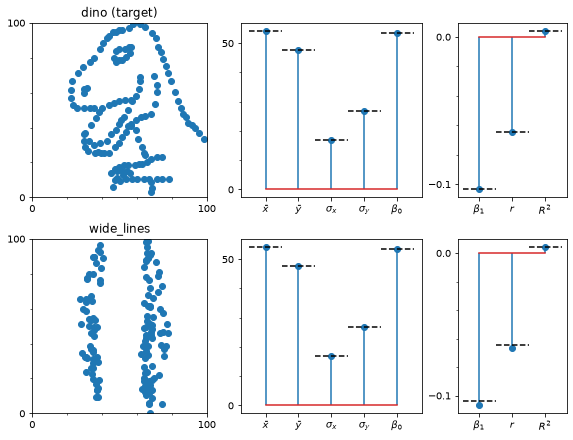

In [2]:
data = torch.load(po.data.fetch_data("datasaurus.tar.gz") / "datasaurus.pt")
categories = np.load(
    po.data.fetch_data("datasaurus.tar.gz") / "categories.npy", allow_pickle=True
)

model = DatasaurusModel(data.shape[1], data.dtype)

fig, axes = plt.subplots(
    2, 3, figsize=(8, 6), width_ratios=[5, 5, 3], layout="compressed"
)
for i, title in enumerate(["dino (target)", "wide_lines"]):
    d = data[categories == title].squeeze()
    single_scatter(d, axes[i, 0], title)
    model.plot_representation(model(d), axes[i, 1:])
    model.plot_representation(model(data)[0], axes[i, 1:], "lines")

Our intended shape here, as can be seen above, is two vertical streaks, about 20 wide with y-values varying from 0 to 100. To encourage metamer synthesis to find such a dataset, we create several functions (all of these show up in other notebooks in this series and so may look familiar):
- `predict_line` returns the y-values for a user-defined line, evaluated at the specified x-values.
- `widelines_penalty` is similar to `lines_penalty` seen in [](ds_xshape.md), among others. However, it subtracts a user-specified margin off the error and throws away all negative values, which allows points to be within margin of the lines, instead of directly on them.
- `vwidelines_penalty` ensures that the input arguments are the proper type and shape, then calls `widelines_penalty`.
- `polygon_penalty`: breaks points into small groups and computes the MSE between the pairwise distances between all the points in each groups and a specified value. Together with `centroid_penalty`, attempts to evenly distribute points across space, see [](ds_polygons.md) for more details.
- `centroid_penalty`: breaks points into small groups and computes the MSE between the pairwise distances between the centroids of all those groups and a specified value. Together with `polygon_penalty`, attempts to evenly distribute points across space, see [](ds_oval.md) for more details.

To use this penalty with synthesis, we define the parameters (try changing these to different values!) and combine the resulting value with a range penalty which requires all points to lie between 0 and 100.

In [3]:
def predict_line(x_vals, intercepts, slope):
    return slope * x_vals + intercepts


def widelines_penalty(data, intercepts, slope, margin):
    # intercepts must be shape [n, 1], slope a scalar or same number of elements as
    # intercepts
    errors = []
    n = data.shape[-1] // intercepts.shape[0]
    # Must either have the same number of slopes and intercepts...
    if hasattr(slope, "__len__") and len(slope) != 1:
        assert len(slope) == len(intercepts)
    else:
        # ...or one intercept
        slope = len(intercepts) * [slope]
    for i, (inter, sl) in enumerate(zip(intercepts, slope)):
        if i != len(intercepts) - 1:
            split = data[..., i * n : (i + 1) * n]
        else:
            # extra entries on last one
            split = data[..., i * n :]
        pred_y = predict_line(split[0], inter, sl)
        err = (split[1] - pred_y).pow(2)
        errors.append((err - margin**2).clip(min=0))
    return torch.mean(torch.cat(errors))


def vwidelines_penalty(data, y_vals, margin):
    intercepts = torch.as_tensor(y_vals).unsqueeze(-1)
    # same as hwidelines, except we swap x and y:
    return widelines_penalty(data[[1, 0]], intercepts, 0, margin)


def polygon_penalty(data, target_dist, nbr):
    # break data into "neighborhoods" of nbr points each and tries to make each of their
    # distances match target i.e., form regular polygons of target size
    pts = einops.rearrange(
        data[..., : nbr * (data.shape[-1] // nbr)], "d (n1 n2) -> n1 n2 d", n2=nbr
    )
    dist = torch.cdist(pts, pts)
    tril_idx = torch.tril_indices(pts.shape[1], pts.shape[1], -1)
    dist = dist[:, tril_idx[0], tril_idx[1]]
    return (dist - target_dist).pow(2).mean()


def centroid_penalty(data, target_dist, nbr):
    pts = einops.rearrange(
        data[..., : nbr * (data.shape[-1] // nbr)], "d (n1 n2) -> n1 n2 d", n2=nbr
    )
    dist = torch.cdist(pts.mean(1), pts.mean(1))
    tril_idx = torch.tril_indices(pts.shape[0], pts.shape[0], -1)
    dist = dist[tril_idx[0], tril_idx[1]]
    return (dist - target_dist).pow(2).mean()


# Try changing these to other values!
x_vals = [30, 70]
margin = 10
polygon_distance = 5
centroid_distance = 25
neighborhood_size = 3


def penalty(x):
    range_penalty = po.regularize.penalize_range(x, (0, 100))
    polygon = polygon_penalty(x, polygon_distance, neighborhood_size)
    centroid = centroid_penalty(x, centroid_distance, neighborhood_size)
    lines = vwidelines_penalty(x, x_vals, margin)
    return range_penalty + lines + polygon + centroid


# data[0] is the dinosaur
met = po.Metamer(data[0], model, penalty_function=penalty, penalty_lambda=0.0005)
met.setup(initial_image=100 * torch.rand_like(data[0]), optimizer=torch.optim.LBFGS)
met.synthesize(50, store_progress=True)

/home/jenkins/agent/workspace/CCN_neurorse_plenoptic_PR-502/lib/python3.12/site-packages/plenoptic/validate.py:101: UserWarning: plenoptic's methods have mostly been tested on 4d inputs with shape torch.Size([n_batch, n_channels, im_height, im_width]). They should theoretically work with different dimensionality; if you have any problems, please open an issue at https://github.com/plenoptic-org/plenoptic/issues/new?template=bug_report.md
  warnings.warn(
/home/jenkins/agent/workspace/CCN_neurorse_plenoptic_PR-502/lib/python3.12/site-packages/plenoptic/validate.py:116: UserWarning: input_tensor range is (2.9487, 99.4872); plenoptic's methods have largely been tested with the range [0, 1]. Synthesis should still work, but if you have any problems, please open an issue.
  warnings.warn(
/home/jenkins/agent/workspace/CCN_neurorse_plenoptic_PR-502/lib/python3.12/site-packages/plenoptic/validate.py:116: UserWarning: input_tensor range is (0.06377352878489395, 99.71721216879205); plenoptic's 

  0%|          | 0/50 [00:00<?, ?it/s]

In [4]:
# use one of our helper functions here.
from plenoptic.plot.display import _rescale_ylim, _update_stem


def penalty_draw(ax):
    for x in x_vals:
        ax.fill_betweenx(
            np.asarray([0, 100]),
            x - margin,
            x + margin,
            zorder=0,
            alpha=0.2,
            color="C0",
        )


def animate_datasaurus_metamer(
    met,
    model=None,
    initial_ylim=None,
    n_frames=50,
    highlight_swap_frame=None,
):
    if model is None:
        model = met.model
    # Initialize figure by plotting the first iteration
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(9, 3),
        width_ratios=[5, 5, 3],
        layout="compressed",
        gridspec_kw={"wspace": 0.25},
    )
    plot_data = met.saved_metamer
    ani_data = po.to_numpy(plot_data)
    ani_rep = po.to_numpy(model(plot_data))
    data_ax = single_scatter(ani_data[0], axes[0])
    penalty_draw(data_ax)

    rep_axes = model.plot_representation(model(data)[0], axes[1:], "lines")
    model.plot_representation(ani_rep[0], rep_axes)
    if initial_ylim is not None:
        rep_axes[1].set(ylim=initial_ylim)
    fig.set_layout_engine("none")

    # In order to avoid this potentially taking a long time, make sure we animate at
    # most n_frames
    frame_step = max(len(plot_data) // n_frames, 1)
    frames = range(0, len(plot_data), frame_step)
    rescale_frames = list(frames)[::10][3:-1]
    if highlight_swap_frame is not None:
        color = "#ffff8144"
        default_color = fig.axes[1].get_facecolor()
        fig.axes[1].set_facecolor(color)
        fig.axes[2].set_facecolor(color)
        fig.suptitle("Phase 1: match statistics")

    # Update the data for each saved iteration.
    def animate(i):
        data_ax.collections[0].set_offsets(ani_data[i].T)
        _update_stem(rep_axes[0].containers[0], ani_rep[i, :5])
        _update_stem(rep_axes[1].containers[0], ani_rep[i, 5:])
        if initial_ylim is not None and i in rescale_frames:
            _rescale_ylim(rep_axes[1], ani_rep[i, 5:])
        color_now = fig.axes[0].get_facecolor()
        if (
            highlight_swap_frame is not None
            and i > highlight_swap_frame
            and color_now == default_color
        ):
            fig.axes[0].set_facecolor(color)
            fig.axes[1].set_facecolor(default_color)
            fig.axes[2].set_facecolor(default_color)
            fig.suptitle("Phase 2: match penalty")

    ani = mpl.animation.FuncAnimation(fig, animate, frames, repeat=False)
    plt.close(fig)

    # This will view the video if running in a jupyter notebook. If you are running
    # outside of a notebook (e.g., in ipython), first save it and then open it with
    # something that can view video files (e.g., your browser) by running:
    # ani.save("ds_vwidelines.mp4")
    return ani


animate_datasaurus_metamer(met, highlight_swap_frame=12)

In the video of the synthesis above, we can see the dataset first shifting itself to become metameric, before moving the points into the vertical regions defined by our penalty. Almost all points end up lying in these regions, which is a success! However, the they do still end up clumping together somewhat, so the `centroid_penalty` and `polygon_penalty` have not been perfectly met. They are doing something important, however, which can be seen by removing them from the definition of `penalty` above.

Interestingly, as in the corresponding dataset in the original datasaurus dozen, the right streak is consistently wider than the left. This consistency implies that this property is required in order for the dataset to be metameric.

In [5]:
import os

from plenoptic.tensors import _check_tensor_equality

if os.environ.get("DATASAURUS_CHECK", False):
    # This cell just tests for reproducibility. As a user, you should skip it -- because
    # pytorch doesn't guarantee reproducibility across CPU/GPU and GPU types, it's
    # unlikely that your results will exactly match ours. (Though it should look
    # approximately as good -- if not, open an issue!)
    cached_met = (
        po.data.fetch_data("datasaurus_metamers.tar.gz") / "datasaurus-vwidelines.pt"
    )
    # just load in the metamer tensor, instead of the whole object
    cached_met = torch.load(cached_met)["_metamer"]
    _check_tensor_equality(
        met.metamer,
        cached_met,
        "Notebook",
        "OSF",
        1e-5,
        1e-7,
        "metamer has different {error_type}! Update the OSF version.",
    )